# All-optical FashionMNIST classification: in situ training of the object arm

Digital twin of the bench. Beyond shaping light, the object arm can compute: a FashionMNIST image is written as phase
$\varphi$ on the $32\times32$ SLM cells, on top of a trainable phase mask $\theta$,

$$X_O = x\odot e^{j\theta},\qquad x = e^{j\varphi},$$

and the light crosses the diffuser. The class is the brightest of ten detector regions of the measured field, with no
digital weights. The mask is trained **in situ**: each training image is displayed once per epoch, its measured field
$\hat O$ forms the error field, and only the adjoint comes from the physical model fitted from ten probes.

| Section | In the manuscript |
|---|---|
| 1 · Bench and physical model | Methods; Supplementary Note 3A |
| 2 · Data | Supplementary Note 3B |
| 3 · Detectors, loss and gradient | Eqs. (2)–(3); Supplementary Note 3B |
| 4 · In situ training | Fig. 2g–i; Methods |
| 5 · Results and the digital baseline | Fig. 2g–i; Supplementary Note 3B |

The optics and methods are in [`twin.py`](twin.py).
Runtime about 3 min on a laptop CPU. FashionMNIST (about 30 MB) is downloaded once into `../data/`.

In [1]:
import os
import gzip
import time
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import twin as tw

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 9})
T_START = time.time()

## 1 · Bench and physical model

Each image is read once, with a long exposure of about 40 pulses, so the per-pulse wavefront jitter averages down
(the `"classification"` bench). As in every session, the screen of the physical model is fitted from ten random probes
(five exposures each).

In [2]:
bench = tw.Bench("classification", seed=0)
rng = np.random.default_rng(7)
X_probe = tw.random_patterns(rng, 10)
model = tw.fit_screen(X_probe, bench.read(X_probe, 5))
X_check = tw.random_patterns(rng, 40)
print(f"model accuracy on 40 held-out random patterns: {tw.model_accuracy(model, X_check, bench.read(X_check, 5)):.3f}")

model accuracy on 40 held-out random patterns: 0.865


## 2 · Data

4,000 FashionMNIST images, 400 per class, split into 2,400 training, 800 validation and 800 test images. Each
$28\times28$ image is resampled to the $32\times32$ cells (area average) and written as phase $\varphi = \pi\,v/255$.

phases (4000, 32, 32), 0..3.14 rad; train / validation / test = 2400 / 800 / 800


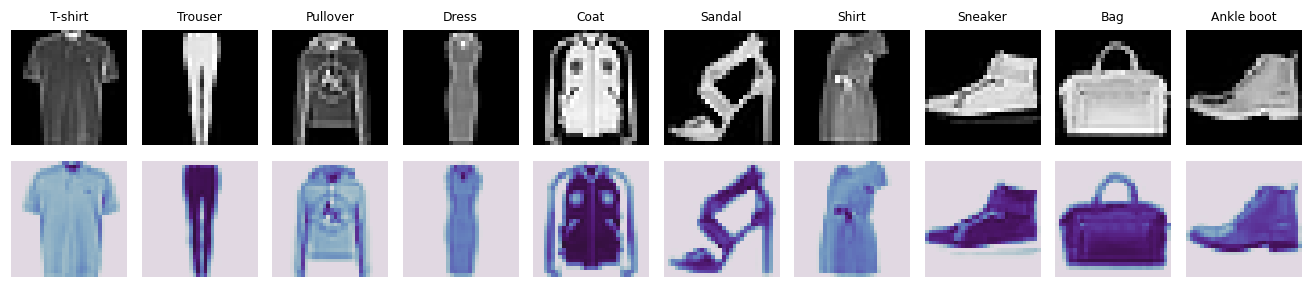

In [3]:
CLASSES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
URL = "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/"
CACHE = os.path.join("..", "data", "fashion_mnist.npz")

if not os.path.exists(CACHE):                       # download once: 70,000 images (train + test files)
    parts = {}
    for name in ["train-images-idx3-ubyte", "train-labels-idx1-ubyte", "t10k-images-idx3-ubyte", "t10k-labels-idx1-ubyte"]:
        raw = gzip.decompress(urllib.request.urlopen(URL + name + ".gz").read())
        parts[name] = np.frombuffer(raw, np.uint8, offset=16 if "images" in name else 8)
    np.savez_compressed(CACHE, X=np.concatenate([parts["train-images-idx3-ubyte"], parts["t10k-images-idx3-ubyte"]]).reshape(-1, 28, 28),
                        y=np.concatenate([parts["train-labels-idx1-ubyte"], parts["t10k-labels-idx1-ubyte"]]))
data = np.load(CACHE)
images, labels = data["X"], data["y"]

g = np.random.default_rng(2026)
idx = np.concatenate([g.choice(np.nonzero(labels == c)[0], 400, replace=False) for c in range(10)])
idx = idx[g.permutation(idx.size)]
edges_in, edges_out = np.linspace(0, 1, 29), np.linspace(0, 1, 33)
R = np.maximum(0, np.minimum(edges_out[1:, None], edges_in[None, 1:]) - np.maximum(edges_out[:-1, None], edges_in[None, :-1]))
R /= R.sum(1, keepdims=True)                        # area resampling 28 -> 32 along one axis
PHI = np.pi * np.einsum("ai,nij,bj->nab", R, images[idx].astype(float), R) / 255
LABELS = labels[idx]
TRAIN, VAL, TEST = np.arange(0, 2400), np.arange(2400, 3200), np.arange(3200, 4000)
print(f"phases {PHI.shape}, 0..{PHI.max():.2f} rad; train / validation / test = {len(TRAIN)} / {len(VAL)} / {len(TEST)}")

fig, axs = plt.subplots(2, 10, figsize=(12, 2.8))
for c in range(10):
    n = TRAIN[LABELS[TRAIN] == c][0]
    axs[0, c].imshow(images[idx[n]], cmap="gray"); axs[0, c].set_title(CLASSES[c], fontsize=8)
    axs[1, c].imshow(PHI[n], cmap="twilight", vmin=0, vmax=2 * np.pi)
for a in axs.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## 3 · Detectors, loss and gradient

Ten square detector regions (16 × 16 samples, 320 µm) in rows of 3–4–3 read the demodulated intensity. With $e_c$ the
energy in detector $c$, the loss is the cross-entropy of the detector energy fractions $f_c = e_c/\sum_{c'}e_{c'}$,
taken as logits with a fixed scale $\tau$ = 100,

$$L = -\big\langle \log \mathrm{softmax}(\tau f)_y\big\rangle_\text{batch},$$

and the predicted class is $\arg\max_c e_c$. The loss depends only on the measured intensity, so $g=\partial L/\partial
|\hat O|^2$ follows from the chain rule through $e_c$, and then, exactly as for focusing and imaging,
$W_n = g_n\odot\hat O_n$ and $\partial L/\partial\theta = \sum_n 2\,\mathrm{Im}[X_n^*\odot T_O^{\mathrm H}\{W_n\}]$.

In [4]:
TAU = 100
BOX = 16
CORNERS = [(-28, -28), (-28, -8), (-28, 12), (-8, -38), (-8, -18), (-8, 2), (-8, 22), (12, -28), (12, -8), (12, 12)]
DETECTORS = np.zeros((10, tw.N, tw.N))
for c, (r0, c0) in enumerate(CORNERS):
    DETECTORS[c, tw.N // 2 + r0:tw.N // 2 + r0 + BOX, tw.N // 2 + c0:tw.N // 2 + c0 + BOX] = 1


def energies(I):
    return np.einsum("nij,cij->nc", I, DETECTORS)


def detector_loss(I, y):
    # cross-entropy of the energy fractions; returns L, dL/dI (n, N, N) and the class probabilities
    e = energies(I)
    E = e.sum(1)
    f = e / E[:, None]
    z = TAU * f
    p = np.exp(z - z.max(1, keepdims=True))
    p /= p.sum(1, keepdims=True)
    n = len(y)
    L = -np.mean(np.log(p[np.arange(n), y]))
    df = TAU * (p - np.eye(10)[y]) / n                                       # dL/df
    g = (np.einsum("nc,cij->nij", df, DETECTORS) - (df * f).sum(1)[:, None, None] * DETECTORS.sum(0)) / E[:, None, None]
    return L, g, p


I_chk = np.abs(model.forward(np.exp(1j * PHI[TRAIN[:4]])))**2
y_chk = LABELS[TRAIN[:4]]
gI = detector_loss(I_chk, y_chk)[1]
d = np.zeros_like(I_chk); d[1, 90, 85] = 1e-6 * I_chk.mean()
fd = (detector_loss(I_chk + d, y_chk)[0] - detector_loss(I_chk - d, y_chk)[0]) / (2 * d[1, 90, 85])
print(f"dL/dI check: chain rule {gI[1, 90, 85]:.5e}, finite difference {fd:.5e}")

dL/dI check: chain rule 5.21229e-04, finite difference 5.21230e-04


## 4 · In situ training

Eight epochs over the 2,400 training images in batches of 25, Adam with learning rate 0.05; every training image costs
one SLM pattern per epoch. After each epoch the mask is read on the 800 validation images; the mask with the best
validation accuracy is tested once on the 800 test images. The untrained mask ($\theta = 0$) with the same detectors is
the control.

In [5]:
def read_intensity(ids, theta):
    return np.abs(bench.read(np.exp(1j * (PHI[ids] + theta))))**2


def accuracy(ids, theta):
    I = read_intensity(ids, theta)
    pred = energies(I).argmax(1)
    return np.mean(pred == LABELS[ids]), pred, I


acc_untrained, pred_untrained, I_untrained = accuracy(TEST, np.zeros((tw.NC, tw.NC)))
print(f"untrained mask: test accuracy {acc_untrained:.3f}")

theta, opt = np.zeros((tw.NC, tw.NC)), tw.Adam((tw.NC, tw.NC), lr=0.05, lr_final=0.05)
order_rng = np.random.default_rng(1)
history = dict(train=[], val=[])
best = dict(val=-1)
patterns_before = bench.patterns
for epoch in range(1, 9):
    order = order_rng.permutation(TRAIN)
    hits = []
    for b in range(0, len(order), 25):
        ids = order[b:b + 25]
        X = np.exp(1j * (PHI[ids] + theta))
        pred = model.forward(X)                                             # the model gives the gauge and the adjoint
        O = np.array([tw.to_model_gauge(o, p) for o, p in zip(bench.read(X), pred)])
        L, g, p = detector_loss(np.abs(O)**2, LABELS[ids])
        theta = opt.step(theta, np.sum(tw.object_gradient(X, g * O, model), axis=0))
        hits.append(np.mean(p.argmax(1) == LABELS[ids]))
    val = accuracy(VAL, theta)[0]
    history["train"].append(np.mean(hits)); history["val"].append(val)
    if val > best["val"]:
        best = dict(val=val, theta=theta.copy(), epoch=epoch)
    print(f"epoch {epoch}: training accuracy {np.mean(hits):.3f}, validation accuracy {val:.3f}")
print(f"in situ training displayed {bench.patterns - patterns_before:,} SLM patterns")

acc_trained, pred_trained, I_trained = accuracy(TEST, best["theta"])
print(f"\ntest accuracy (best validation epoch {best['epoch']}): untrained {acc_untrained:.3f} -> trained {acc_trained:.3f}")

untrained mask: test accuracy 0.133


epoch 1: training accuracy 0.411, validation accuracy 0.591


epoch 2: training accuracy 0.621, validation accuracy 0.651


epoch 3: training accuracy 0.674, validation accuracy 0.700


epoch 4: training accuracy 0.698, validation accuracy 0.704


epoch 5: training accuracy 0.712, validation accuracy 0.713


epoch 6: training accuracy 0.735, validation accuracy 0.689


epoch 7: training accuracy 0.740, validation accuracy 0.710


epoch 8: training accuracy 0.752, validation accuracy 0.745
in situ training displayed 25,600 SLM patterns



test accuracy (best validation epoch 8): untrained 0.133 -> trained 0.745


## 5 · Results

Mean measured intensity of the test images of each class, with the ten detectors (true class in white), before and
after training (cf. Fig. 2g–i). The trained mask moves only a small share of the light, so the class means look alike
by eye; the confusion matrix and the share of light that reaches the true detector show what changed.

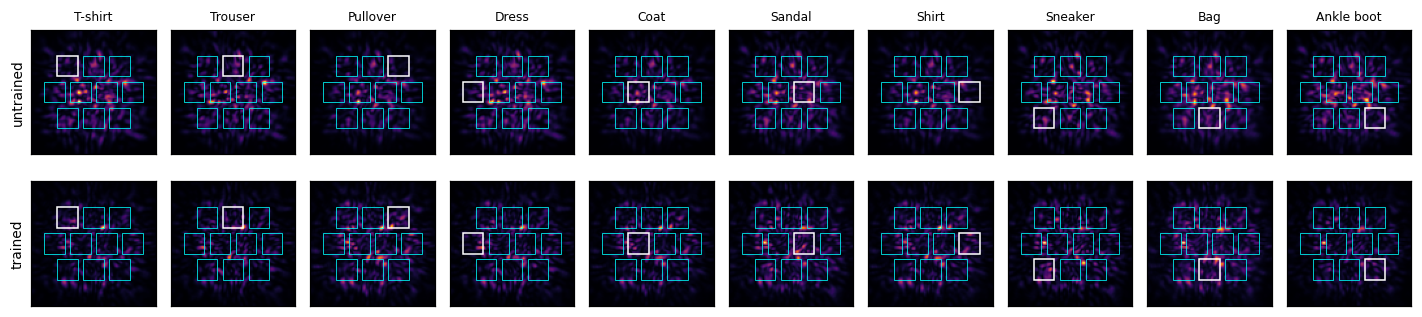

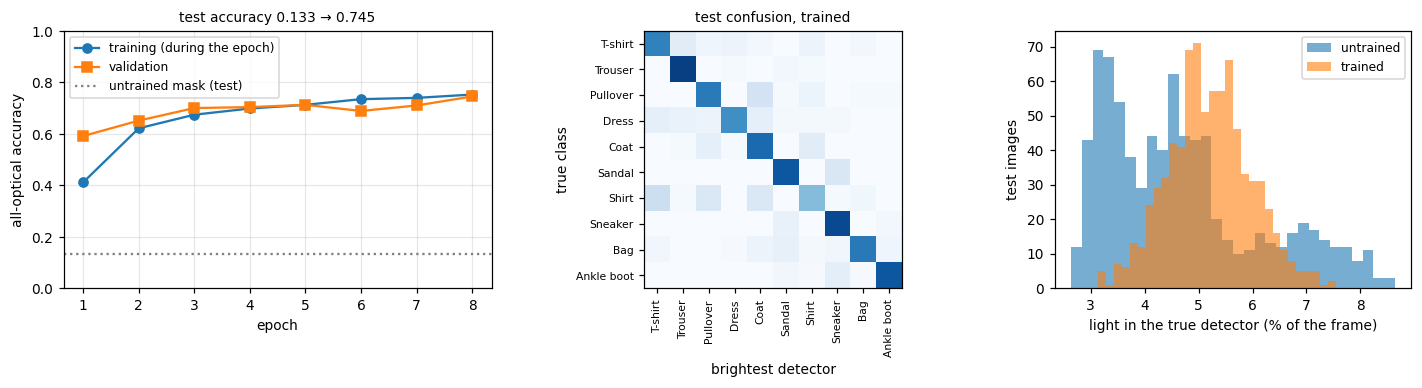

In [6]:
z = slice(tw.N // 2 - 48, tw.N // 2 + 48)


def draw_detectors(ax, true_class):
    for k, (r0, c0) in enumerate(CORNERS):
        ax.add_patch(Rectangle((48 + c0 - 0.5, 48 + r0 - 0.5), BOX, BOX, fill=False, lw=1.0 if k == true_class else 0.5,
                               color="white" if k == true_class else "cyan"))


fig, axs = plt.subplots(2, 10, figsize=(13, 3.2))
for row, (I, title) in enumerate([(I_untrained, "untrained"), (I_trained, "trained")]):
    for c in range(10):
        axs[row, c].imshow(I[LABELS[TEST] == c].mean(0)[z, z], cmap="inferno")
        draw_detectors(axs[row, c], c)
        axs[row, c].set_xticks([]); axs[row, c].set_yticks([])
        if row == 0: axs[row, c].set_title(CLASSES[c], fontsize=8)
    axs[row, 0].set_ylabel(title)
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw=dict(width_ratios=[1.2, 1, 1]))
ep = np.arange(1, 9)
axs[0].plot(ep, history["train"], "o-", label="training (during the epoch)")
axs[0].plot(ep, history["val"], "s-", label="validation")
axs[0].axhline(acc_untrained, color="gray", ls=":", label="untrained mask (test)")
axs[0].set_xlabel("epoch"); axs[0].set_ylabel("all-optical accuracy"); axs[0].set_ylim(0, 1); axs[0].grid(alpha=0.3)
axs[0].legend(fontsize=8); axs[0].set_title(f"test accuracy {acc_untrained:.3f} → {acc_trained:.3f}")
cm = np.zeros((10, 10))
for t, p in zip(LABELS[TEST], pred_trained): cm[t, p] += 1
axs[1].imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
axs[1].set_xticks(range(10)); axs[1].set_yticks(range(10))
axs[1].set_xticklabels(CLASSES, rotation=90, fontsize=7); axs[1].set_yticklabels(CLASSES, fontsize=7)
axs[1].set_xlabel("brightest detector"); axs[1].set_ylabel("true class"); axs[1].set_title("test confusion, trained")
share = lambda I: energies(I)[np.arange(len(TEST)), LABELS[TEST]] / I.sum(axis=(1, 2))
axs[2].hist(100 * share(I_untrained), bins=30, alpha=0.6, label="untrained")
axs[2].hist(100 * share(I_trained), bins=30, alpha=0.6, label="trained")
axs[2].set_xlabel("light in the true detector (% of the frame)"); axs[2].set_ylabel("test images")
axs[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Digital baseline.** A logistic regression on the same $32\times32$ input phases, trained digitally on the same split
(Supplementary Note 3B: 82.9 % on the bench data). It is a reference point, not an optical result.

In [7]:
Xd = PHI.reshape(len(PHI), -1)
Xd = (Xd - Xd[TRAIN].mean(0)) / (Xd[TRAIN].std(0) + 1e-6)
Wd, bd = np.zeros((Xd.shape[1], 10)), np.zeros(10)
opt_w, opt_b = tw.Adam(Wd.shape, 0.01, 0.01), tw.Adam(bd.shape, 0.01, 0.01)
for _ in range(300):
    zl = Xd[TRAIN] @ Wd + bd
    p = np.exp(zl - zl.max(1, keepdims=True)); p /= p.sum(1, keepdims=True)
    dz = (p - np.eye(10)[LABELS[TRAIN]]) / len(TRAIN)
    Wd, bd = opt_w.step(Wd, Xd[TRAIN].T @ dz + 1e-3 * Wd), opt_b.step(bd, dz.sum(0))
acc_digital = np.mean((Xd[TEST] @ Wd + bd).argmax(1) == LABELS[TEST])

print(f"{'classifier':40s} {'test accuracy':>14s}")
for name, a in [("chance", 0.1), ("optical, untrained mask", acc_untrained), ("optical, mask trained in situ", acc_trained),
                ("digital logistic regression on the input", acc_digital)]:
    print(f"{name:40s} {a:14.3f}")
print(f"\nSLM patterns displayed in this notebook: {bench.patterns:,}; runtime {time.time() - T_START:.0f} s")

classifier                                test accuracy
chance                                            0.100
optical, untrained mask                           0.133
optical, mask trained in situ                     0.745
digital logistic regression on the input          0.820

SLM patterns displayed in this notebook: 27,250; runtime 119 s


**Take-aways.** Trained in situ through a ten-probe model, one phase mask in front of the
diffuser turns the brightest of ten detectors into a FashionMNIST classifier: the all-optical test accuracy rises from
0.13 with the untrained mask to about 0.75, below the 0.82 of a digital logistic regression on the input (bench:
17.8 % → 75.0 %, logistic regression 82.9 %, Supplementary Note 3B).